In [1]:
import pandas as pd
import numpy as np

# Consider the following Python dictionary data and Python list labels:

```
data = {'birds': ['Cranes', 'Cranes', 'plovers', 'spoonbills', 'spoonbills', 'Cranes', 'plovers', 'Cranes', 'spoonbills', 'spoonbills', 'Cranes'],
        'age': [3.5, 4, 1.5, np.nan, 6, 3, 5.5, np.nan, 8, 4, 3.5], 'visits': [2, 4, 3, 4, 3, 4, 2, 2, 3, 2, 2],
        'priority': ['yes', 'yes', 'no', np.nan, 'no', 'no', 'no', 'yes', 'no', 'no','yes']}
```
```
labels = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k']
```

# `Q-1:`
i. Create a DataFrame birds from the above dictionary data which has the index labels.

ii. Display basic information about the dataFrame.

iii. Show Alternate rows of the dataframe.

In [2]:
# 1)  Create a DataFrame birds from the above dictionary data which has the index labels.

data = data = {
    'birds': ['Cranes', 'Cranes', 'plovers', 'spoonbills', 'spoonbills', 'Cranes', 'plovers', 'Cranes', 'spoonbills', 'spoonbills', 'Cranes'],
    'age': [3.5, 4, 1.5, np.nan, 6, 3, 5.5, np.nan, 8, 4, 3.5],
    'visits': [2, 4, 3, 4, 3, 4, 2, 2, 3, 2, 2],
    'priority': ['yes', 'yes', 'no', np.nan, 'no', 'no', 'no', 'yes', 'no', 'no','yes']
}

labels = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k']

birds = pd.DataFrame(data, index = labels)

In [3]:
birds

,birds,age,visits,priority
a,Cranes,3.5,2,yes
b,Cranes,4.0,4,yes
c,plovers,1.5,3,no
d,spoonbills,NaN,4,NaN
e,spoonbills,6.0,3,no
f,Cranes,3.0,4,no
g,plovers,5.5,2,no
h,Cranes,NaN,2,yes
i,spoonbills,8.0,3,no
j,spoonbills,4.0,2,no


In [4]:
# 2) Display basic information about the dataFrame.

print(birds.describe())
print()
print()
print()

print(birds.columns)
print()
print()
print()

print(birds.index)

            age     visits
count  9.000000  11.000000
mean   4.333333   2.818182
std    1.903943   0.873863
min    1.500000   2.000000
25%    3.500000   2.000000
50%    4.000000   3.000000
75%    5.500000   3.500000
max    8.000000   4.000000



Index(['birds', 'age', 'visits', 'priority'], dtype='object')



Index(['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k'], dtype='object')


In [5]:
# 3) Show Alternate rows of the dataframe.

birds[::2]

,birds,age,visits,priority
a,Cranes,3.5,2,yes
c,plovers,1.5,3,no
e,spoonbills,6.0,3,no
g,plovers,5.5,2,no
i,spoonbills,8.0,3,no
k,Cranes,3.5,2,yes


# Question - 2: 

i. Show only rows [1st, 3rd, 7th] from columns ['bird', 'age']

ii. Select rows where the number of visits is less than 4.

In [6]:
# 2) Show only rows [1st, 3rd, 7th] from columns ['bird', 'age']

birds.iloc[[0, 2, 6], [0, 1]]   # rows-->[0, 2, 6] and columns--> [0, 1] 

,birds,age
a,Cranes,3.5
c,plovers,1.5
g,plovers,5.5


In [7]:
# 2) Select rows where the number of visits is less than 4.

birds[birds['visits'] < 4]

,birds,age,visits,priority
a,Cranes,3.5,2,yes
c,plovers,1.5,3,no
e,spoonbills,6.0,3,no
g,plovers,5.5,2,no
h,Cranes,NaN,2,yes
i,spoonbills,8.0,3,no
j,spoonbills,4.0,2,no
k,Cranes,3.5,2,yes


# Question - 3: 

i. Select all rows with nan values in age and visits column.

ii. Fill nan with respective series mode value.

In [8]:
# 1) Select all rows with nan values in age and visits column.

birds[birds[['age', 'visits']].isnull().any(axis = 1)]

,birds,age,visits,priority
d,spoonbills,NaN,4,NaN
h,Cranes,NaN,2,yes


In [9]:
birds.isnull().sum()

birds       0
age         2
visits      0
priority    1
dtype: int64

In [10]:
mode_age = birds['age'].mode()[0]
mode_priority = birds['priority'].mode()[0]

In [11]:
fill_values = {
    'age': mode_age,
    'priority': mode_priority
}

birds = birds.fillna(fill_values)

birds

,birds,age,visits,priority
a,Cranes,3.5,2,yes
b,Cranes,4.0,4,yes
c,plovers,1.5,3,no
d,spoonbills,3.5,4,no
e,spoonbills,6.0,3,no
f,Cranes,3.0,4,no
g,plovers,5.5,2,no
h,Cranes,3.5,2,yes
i,spoonbills,8.0,3,no
j,spoonbills,4.0,2,no


In [12]:
birds.isnull().sum()

birds       0
age         0
visits      0
priority    0
dtype: int64

# Question-4

i. Find the total number of visits of the bird Cranes

ii. Find the number of each type of birds in dataframe.

iii. Print no of duplicate rows

iv. Drop Duplicates rows and make this changes permanent. Show dataframe after changes.

In [13]:
# 1) Find the total number of visits of the bird Cranes

birds[birds['birds'] == 'Cranes'] ['visits'].sum()

14

In [14]:
# second way: bus using 'groupby() and get_group()' methods.

birds.groupby('birds').get_group('Cranes')['visits'].sum()

14

In [15]:
# 2) Find the number of each type of birds in dataframe.

birds['birds'].value_counts()

Cranes        5
spoonbills    4
plovers       2
Name: birds, dtype: int64

In [16]:
(birds['birds'] == 'Cranes').sum()   # To verify the above results are riight or wrong

5

In [17]:
# 3) Print no of duplicate rows

birds[birds.duplicated(keep = False)]

,birds,age,visits,priority
a,Cranes,3.5,2,yes
h,Cranes,3.5,2,yes
k,Cranes,3.5,2,yes


In [18]:
birds.duplicated(keep = False).sum()

# Keep = first/ last/ False

# first (by-default) --> marks duplicates as True except on the first occurance
# last--> marks duplicates as True except on the last occurance
# False--> marks duplicates as True on all the occurances

# Here we used False bcz we wanted the total duplicate values.

3

In [19]:
# 4) Drop Duplicates rows and make this changes permanent. Show dataframe after changes.

birds.drop_duplicates(inplace = True)

# first (by-default)--> Keeps the first occurance and drops the rest
# last--> Keeps the last occurance and drops the rest
# False--> Drops all the duplicate rows

# Here we used False bcz we wanted the total duplicate values.

birds

,birds,age,visits,priority
a,Cranes,3.5,2,yes
b,Cranes,4.0,4,yes
c,plovers,1.5,3,no
d,spoonbills,3.5,4,no
e,spoonbills,6.0,3,no
f,Cranes,3.0,4,no
g,plovers,5.5,2,no
i,spoonbills,8.0,3,no
j,spoonbills,4.0,2,no


In [20]:
birds

,birds,age,visits,priority
a,Cranes,3.5,2,yes
b,Cranes,4.0,4,yes
c,plovers,1.5,3,no
d,spoonbills,3.5,4,no
e,spoonbills,6.0,3,no
f,Cranes,3.0,4,no
g,plovers,5.5,2,no
i,spoonbills,8.0,3,no
j,spoonbills,4.0,2,no


# New dataset - IPL matches dataset betweeen 2008-2022

Q-5: In IPL matches dataset some teams name has changed. You will have to consider them as same.

'Delhi Capitals' formerly as 'Delhi Daredevils'
'Punjab Kings' formerly as 'Kings XI Punjab'
'Rising Pune Supergiant' formerly as 'Rising Pune Supergiants'
You need to make changes accordingly. Consider current name for each teams.

Be careful Gujrat Titans and Gujrat Lions are different teams.

In [21]:
ipl = pd.read_csv(r"00 Task 17 ipl_dataset.csv")

ipl.head()

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,SuperOver,WinningTeam,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2
0,1312200,Ahmedabad,2022-05-29,2022,Final,Rajasthan Royals,Gujarat Titans,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,bat,N,Gujarat Titans,Wickets,7.0,NaN,HH Pandya,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",CB Gaffaney,Nitin Menon
1,1312199,Ahmedabad,2022-05-27,2022,Qualifier 2,Royal Challengers Bangalore,Rajasthan Royals,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,field,N,Rajasthan Royals,Wickets,7.0,NaN,JC Buttler,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",CB Gaffaney,Nitin Menon
2,1312198,Kolkata,2022-05-25,2022,Eliminator,Royal Challengers Bangalore,Lucknow Super Giants,"Eden Gardens, Kolkata",Lucknow Super Giants,field,N,Royal Challengers Bangalore,Runs,14.0,NaN,RM Patidar,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['Q de Kock', 'KL Rahul', 'M Vohra', 'DJ Hooda...",J Madanagopal,MA Gough
3,1312197,Kolkata,2022-05-24,2022,Qualifier 1,Rajasthan Royals,Gujarat Titans,"Eden Gardens, Kolkata",Gujarat Titans,field,N,Gujarat Titans,Wickets,7.0,NaN,DA Miller,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",BNJ Oxenford,VK Sharma
4,1304116,Mumbai,2022-05-22,2022,70,Sunrisers Hyderabad,Punjab Kings,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,bat,N,Punjab Kings,Wickets,5.0,NaN,Harpreet Brar,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ...","['JM Bairstow', 'S Dhawan', 'M Shahrukh Khan',...",AK Chaudhary,NA Patwardhan


In [22]:
ipl.dtypes

ID                   int64
City                object
Date                object
Season              object
MatchNumber         object
Team1               object
Team2               object
Venue               object
TossWinner          object
TossDecision        object
SuperOver           object
WinningTeam         object
WonBy               object
Margin             float64
method              object
Player_of_Match     object
Team1Players        object
Team2Players        object
Umpire1             object
Umpire2             object
dtype: object

In [23]:
ipl['Date'] = pd.to_datetime(ipl['Date'])    # Just tried

In [24]:
ipl.dtypes

ID                          int64
City                       object
Date               datetime64[ns]
Season                     object
MatchNumber                object
Team1                      object
Team2                      object
Venue                      object
TossWinner                 object
TossDecision               object
SuperOver                  object
WinningTeam                object
WonBy                      object
Margin                    float64
method                     object
Player_of_Match            object
Team1Players               object
Team2Players               object
Umpire1                    object
Umpire2                    object
dtype: object

In [25]:
ipl['Team1'].value_counts()

Royal Challengers Bangalore    126
Mumbai Indians                 112
Chennai Super Kings            111
Kolkata Knight Riders          105
Kings XI Punjab                 92
Rajasthan Royals                89
Delhi Daredevils                85
Sunrisers Hyderabad             69
Deccan Chargers                 39
Delhi Capitals                  29
Pune Warriors                   23
Punjab Kings                    18
Gujarat Lions                   16
Lucknow Super Giants             8
Gujarat Titans                   7
Rising Pune Supergiant           7
Rising Pune Supergiants          7
Kochi Tuskers Kerala             7
Name: Team1, dtype: int64

In [26]:
# 1) Changing the names of the teams as current names

# 'Delhi Capitals' from 'Delhi Daredevils'
# 'Punjab Kings' from 'Kings XI Punjab'
# 'Rising Pune Supergiant' from 'Rising Pune Supergiants'

ipl['Team1'] = ipl['Team1'].replace('Delhi Daredevils', 'Delhi Capitals')



In [27]:
replace = {
    'Kings XI Punjab': 'Punjab Kings',
    'Rising Pune Supergiants': 'Rising Pune Supergiant',
    'Gujarat Titans': 'Gujarat Lions',
    'Deccan Chargers': 'Sunrisers Hyderabad',
    'Pune Warriors': 'Rising Pune Supergiant'
}



ipl['Team1'] = ipl['Team1'].replace(replace)

In [28]:
# Replacing in Team2

replace2 = {
    'Kings XI Punjab': 'Punjab Kings',
    'Rising Pune Supergiants': 'Rising Pune Supergiant',    # Removed 's' from 'Supergiants'
    'Delhi Daredevils': 'Delhi Capitals',
    'Gujarat Titans': 'Gujarat Lions',
    'Deccan Chargers': 'Sunrisers Hyderabad',
    'Pune Warriors': 'Rising Pune Supergiant'
}



ipl['Team2'] = ipl['Team2'].replace(replace2)

In [29]:
ipl['Team1'].value_counts()

Royal Challengers Bangalore    126
Delhi Capitals                 114
Mumbai Indians                 112
Chennai Super Kings            111
Punjab Kings                   110
Sunrisers Hyderabad            108
Kolkata Knight Riders          105
Rajasthan Royals                89
Rising Pune Supergiant          37
Gujarat Lions                   23
Lucknow Super Giants             8
Kochi Tuskers Kerala             7
Name: Team1, dtype: int64

In [30]:
ipl['WinningTeam'] = ipl['WinningTeam'].replace(replace2)

# `Question 6`: Write a code which can display the bar chart of top 5 teams who have played maximum number of matches in the IPL.

Hint: Be careful the data is divided in 2 different cols(Team 1 and Team 2)

In [31]:
# Let's sum value_counts() of Team1 and Team2

matches_per_team = ((ipl['Team1'].value_counts()) + ipl['Team2'].value_counts()).sort_values(ascending = False)

matches_per_team

Mumbai Indians                 231
Sunrisers Hyderabad            227
Royal Challengers Bangalore    226
Delhi Capitals                 224
Kolkata Knight Riders          223
Punjab Kings                   218
Chennai Super Kings            208
Rajasthan Royals               192
Rising Pune Supergiant          76
Gujarat Lions                   46
Lucknow Super Giants            15
Kochi Tuskers Kerala            14
dtype: int64

<AxesSubplot: >

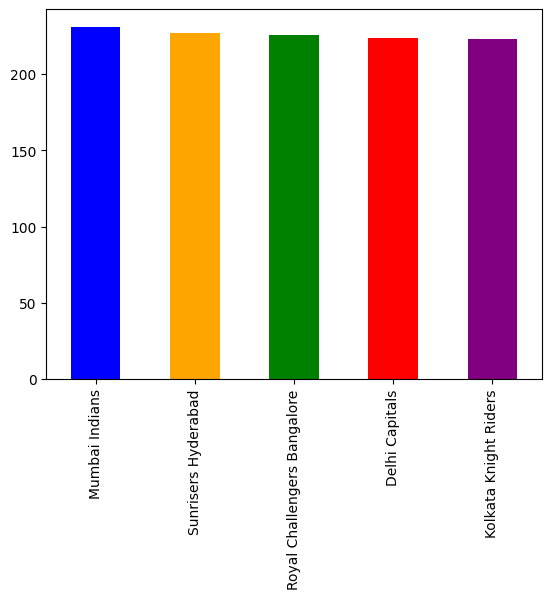

In [32]:
# Creating a bar chart of top 5 teams

matches_per_team.head().plot(kind = 'bar', color = ['blue', 'orange', 'green', 'red', 'purple'])

# `Question 7`: Player who got Most no. of Man of the match award playing against Mumbai Indians.

` Assume that the winning team won the **Man of the Match** award`

So first of all find all those matches (From Team 1 and Team 2 both) where Mumbai Indians is playing. <br>
Then from it, select all those records where Mumbai Indians lost and oponent won. <br>
Then value_counts() on 'Player_of_match' column to get most against MI

In [33]:
ipl.head()

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,SuperOver,WinningTeam,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2
0,1312200,Ahmedabad,2022-05-29,2022,Final,Rajasthan Royals,Gujarat Lions,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,bat,N,Gujarat Lions,Wickets,7.0,NaN,HH Pandya,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",CB Gaffaney,Nitin Menon
1,1312199,Ahmedabad,2022-05-27,2022,Qualifier 2,Royal Challengers Bangalore,Rajasthan Royals,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,field,N,Rajasthan Royals,Wickets,7.0,NaN,JC Buttler,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",CB Gaffaney,Nitin Menon
2,1312198,Kolkata,2022-05-25,2022,Eliminator,Royal Challengers Bangalore,Lucknow Super Giants,"Eden Gardens, Kolkata",Lucknow Super Giants,field,N,Royal Challengers Bangalore,Runs,14.0,NaN,RM Patidar,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['Q de Kock', 'KL Rahul', 'M Vohra', 'DJ Hooda...",J Madanagopal,MA Gough
3,1312197,Kolkata,2022-05-24,2022,Qualifier 1,Rajasthan Royals,Gujarat Lions,"Eden Gardens, Kolkata",Gujarat Titans,field,N,Gujarat Lions,Wickets,7.0,NaN,DA Miller,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",BNJ Oxenford,VK Sharma
4,1304116,Mumbai,2022-05-22,2022,70,Sunrisers Hyderabad,Punjab Kings,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,bat,N,Punjab Kings,Wickets,5.0,NaN,Harpreet Brar,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ...","['JM Bairstow', 'S Dhawan', 'M Shahrukh Khan',...",AK Chaudhary,NA Patwardhan


In [34]:
mi_matches = ipl[
            
            (ipl['Team1'] == 'Mumbai Indians') | 
            (ipl['Team2'] == 'Mumbai Indians')
            ]

mi_matches

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,SuperOver,WinningTeam,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2
5,1304115,Mumbai,2022-05-21,2022,69,Delhi Capitals,Mumbai Indians,"Wankhede Stadium, Mumbai",Mumbai Indians,field,N,Mumbai Indians,Wickets,5.0,NaN,JJ Bumrah,"['PP Shaw', 'DA Warner', 'MR Marsh', 'RR Pant'...","['Ishan Kishan', 'RG Sharma', 'D Brevis', 'Til...",Nitin Menon,Tapan Sharma
9,1304111,Mumbai,2022-05-17,2022,65,Sunrisers Hyderabad,Mumbai Indians,"Wankhede Stadium, Mumbai",Mumbai Indians,field,N,Sunrisers Hyderabad,Runs,3.0,NaN,RA Tripathi,"['Abhishek Sharma', 'PK Garg', 'RA Tripathi', ...","['RG Sharma', 'Ishan Kishan', 'DR Sams', 'Tila...",CB Gaffaney,N Pandit
15,1304105,Mumbai,2022-05-12,2022,59,Chennai Super Kings,Mumbai Indians,"Wankhede Stadium, Mumbai",Mumbai Indians,field,N,Mumbai Indians,Wickets,5.0,NaN,DR Sams,"['RD Gaikwad', 'DP Conway', 'MM Ali', 'RV Utha...","['Ishan Kishan', 'RG Sharma', 'DR Sams', 'Tila...",Chirra Ravikanthreddy,CB Gaffaney
18,1304102,Navi Mumbai,2022-05-09,2022,56,Kolkata Knight Riders,Mumbai Indians,"Dr DY Patil Sports Academy, Mumbai",Mumbai Indians,field,N,Kolkata Knight Riders,Runs,52.0,NaN,JJ Bumrah,"['VR Iyer', 'AM Rahane', 'N Rana', 'SS Iyer', ...","['RG Sharma', 'Ishan Kishan', 'Tilak Varma', '...",CB Gaffaney,GR Sadashiv Iyer
23,1304097,Mumbai,2022-05-06,2022,51,Mumbai Indians,Gujarat Lions,"Brabourne Stadium, Mumbai",Gujarat Titans,field,N,Mumbai Indians,Runs,5.0,NaN,TH David,"['Ishan Kishan', 'RG Sharma', 'SA Yadav', 'Til...","['WP Saha', 'Shubman Gill', 'HH Pandya', 'B Sa...",J Madanagopal,GR Sadashiv Iyer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
934,335997,Kolkata,2008-04-29,2007/08,16,Kolkata Knight Riders,Mumbai Indians,Eden Gardens,Kolkata Knight Riders,bat,N,Mumbai Indians,Wickets,7.0,NaN,ST Jayasuriya,"['BB McCullum', 'SC Ganguly', 'RT Ponting', 'D...","['AM Rahane', 'ST Jayasuriya', 'MK Pandey', 'R...",BF Bowden,AV Jayaprakash
937,335994,Mumbai,2008-04-27,2007/08,14,Mumbai Indians,Sunrisers Hyderabad,Dr DY Patil Sports Academy,Deccan Chargers,field,N,Sunrisers Hyderabad,Wickets,10.0,NaN,AC Gilchrist,"['L Ronchi', 'ST Jayasuriya', 'AM Rahane', 'RV...","['AC Gilchrist', 'VVS Laxman', 'A Symonds', 'R...",Asad Rauf,SL Shastri
940,335991,Chandigarh,2008-04-25,2007/08,10,Punjab Kings,Mumbai Indians,"Punjab Cricket Association Stadium, Mohali",Mumbai Indians,field,N,Punjab Kings,Runs,66.0,NaN,KC Sangakkara,"['K Goel', 'IK Pathan', 'KC Sangakkara', 'Yuvr...","['L Ronchi', 'ST Jayasuriya', 'RV Uthappa', 'D...",Aleem Dar,AM Saheba
942,335989,Chennai,2008-04-23,2007/08,8,Chennai Super Kings,Mumbai Indians,"MA Chidambaram Stadium, Chepauk",Mumbai Indians,field,N,Chennai Super Kings,Runs,6.0,NaN,ML Hayden,"['PA Patel', 'ML Hayden', 'MEK Hussey', 'SK Ra...","['L Ronchi', 'ST Jayasuriya', 'RV Uthappa', 'S...",DJ Harper,GA Pratapkumar


In [35]:
# Filtering those matches where Mumbai Indians lost
# Means 'WinningTeam' != 'Mumbai Indians'

mi_lost = mi_matches[mi_matches['WinningTeam'] != 'Mumbai Indians']

# Mumbai Indians lost. It means Man_of_the_match award is won by the oponent team

mi_lost

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,SuperOver,WinningTeam,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2
9,1304111,Mumbai,2022-05-17,2022,65,Sunrisers Hyderabad,Mumbai Indians,"Wankhede Stadium, Mumbai",Mumbai Indians,field,N,Sunrisers Hyderabad,Runs,3.0,NaN,RA Tripathi,"['Abhishek Sharma', 'PK Garg', 'RA Tripathi', ...","['RG Sharma', 'Ishan Kishan', 'DR Sams', 'Tila...",CB Gaffaney,N Pandit
18,1304102,Navi Mumbai,2022-05-09,2022,56,Kolkata Knight Riders,Mumbai Indians,"Dr DY Patil Sports Academy, Mumbai",Mumbai Indians,field,N,Kolkata Knight Riders,Runs,52.0,NaN,JJ Bumrah,"['VR Iyer', 'AM Rahane', 'N Rana', 'SS Iyer', ...","['RG Sharma', 'Ishan Kishan', 'Tilak Varma', '...",CB Gaffaney,GR Sadashiv Iyer
37,1304083,Mumbai,2022-04-24,2022,37,Lucknow Super Giants,Mumbai Indians,"Wankhede Stadium, Mumbai",Mumbai Indians,field,N,Lucknow Super Giants,Runs,36.0,NaN,KL Rahul,"['Q de Kock', 'KL Rahul', 'MK Pandey', 'MP Sto...","['Ishan Kishan', 'RG Sharma', 'D Brevis', 'SA ...",M Erasmus,HAS Khalid
41,1304079,Navi Mumbai,2022-04-21,2022,33,Mumbai Indians,Chennai Super Kings,"Dr DY Patil Sports Academy, Mumbai",Chennai Super Kings,field,N,Chennai Super Kings,Wickets,3.0,NaN,Mukesh Choudhary,"['RG Sharma', 'Ishan Kishan', 'D Brevis', 'SA ...","['RD Gaikwad', 'RV Uthappa', 'MJ Santner', 'AT...",BNJ Oxenford,UV Gandhe
48,1304072,Mumbai,2022-04-16,2022,26,Lucknow Super Giants,Mumbai Indians,"Brabourne Stadium, Mumbai",Mumbai Indians,field,N,Lucknow Super Giants,Runs,18.0,NaN,KL Rahul,"['KL Rahul', 'Q de Kock', 'MK Pandey', 'MP Sto...","['Ishan Kishan', 'RG Sharma', 'D Brevis', 'SA ...",AK Chaudhary,NA Patwardhan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
905,336028,Mumbai,2008-05-21,2007/08,45,Mumbai Indians,Punjab Kings,Wankhede Stadium,Mumbai Indians,field,N,Punjab Kings,Runs,1.0,NaN,SE Marsh,"['ST Jayasuriya', 'SR Tendulkar', 'DR Smith', ...","['SE Marsh', 'JR Hopes', 'LA Pomersbach', 'Yuv...",BF Bowden,GA Pratapkumar
937,335994,Mumbai,2008-04-27,2007/08,14,Mumbai Indians,Sunrisers Hyderabad,Dr DY Patil Sports Academy,Deccan Chargers,field,N,Sunrisers Hyderabad,Wickets,10.0,NaN,AC Gilchrist,"['L Ronchi', 'ST Jayasuriya', 'AM Rahane', 'RV...","['AC Gilchrist', 'VVS Laxman', 'A Symonds', 'R...",Asad Rauf,SL Shastri
940,335991,Chandigarh,2008-04-25,2007/08,10,Punjab Kings,Mumbai Indians,"Punjab Cricket Association Stadium, Mohali",Mumbai Indians,field,N,Punjab Kings,Runs,66.0,NaN,KC Sangakkara,"['K Goel', 'IK Pathan', 'KC Sangakkara', 'Yuvr...","['L Ronchi', 'ST Jayasuriya', 'RV Uthappa', 'D...",Aleem Dar,AM Saheba
942,335989,Chennai,2008-04-23,2007/08,8,Chennai Super Kings,Mumbai Indians,"MA Chidambaram Stadium, Chepauk",Mumbai Indians,field,N,Chennai Super Kings,Runs,6.0,NaN,ML Hayden,"['PA Patel', 'ML Hayden', 'MEK Hussey', 'SK Ra...","['L Ronchi', 'ST Jayasuriya', 'RV Uthappa', 'S...",DJ Harper,GA Pratapkumar


In [36]:
# Then value_counts() on 'Player_of_match' column to get most against MI

mi_lost['Player_of_Match'].value_counts()    

# SPD Smith, KL Rahul and Raina won most Man_of_the_Match awards against MI

SPD Smith     4
KL Rahul      4
SK Raina      4
JH Kallis     3
CH Gayle      3
             ..
JJ Bumrah     1
AJ Finch      1
SS Iyer       1
GJ Bailey     1
MV Boucher    1
Name: Player_of_Match, Length: 68, dtype: int64

In [37]:
mi_lost['Player_of_Match'].value_counts().index[0]

'SPD Smith'

In [38]:
mi_lost['Player_of_Match'].value_counts().idxmax()

'SPD Smith'

# `Question 8`: Create a function which will take two string(name of two teams) as input. Show win Loss record between them and player getting most player of the match award in matches between these two teams. 

`For eg. team1_vs_team2('Kolkata Knight Riders','Chennai Super Kings')`


# There're three questions here.
1.  `Show win Loss record between two teams`: Fetch columns Team1, Team2 and WinningTeam
3.  `Player getting most player of the match award in matches between these two teams`: : Same as the previous question

In [39]:
def team1_vs_team2(x, y):

    matches = ipl [
    (ipl['Team1'] == x) &
    (ipl['Team2'] == y) |
    (ipl['Team1'] == y) &
    (ipl['Team2'] == x)
    ]

    records = matches[['Team1', 'Team2', 'WinningTeam']]

    most_man_of_match = matches['Player_of_Match'].value_counts().index[0]

    return records, f'Player with most Man of the Match award: {most_man_of_match}'

In [40]:
a = team1_vs_team2('Mumbai Indians', 'Chennai Super Kings')

In [41]:
type(a)

tuple

In [42]:
a

(                   Team1                Team2          WinningTeam
 15   Chennai Super Kings       Mumbai Indians       Mumbai Indians
 41        Mumbai Indians  Chennai Super Kings  Chennai Super Kings
 104  Chennai Super Kings       Mumbai Indians  Chennai Super Kings
 107  Chennai Super Kings       Mumbai Indians       Mumbai Indians
 153  Chennai Super Kings       Mumbai Indians       Mumbai Indians
 193       Mumbai Indians  Chennai Super Kings  Chennai Super Kings
 194       Mumbai Indians  Chennai Super Kings       Mumbai Indians
 197  Chennai Super Kings       Mumbai Indians       Mumbai Indians
 210       Mumbai Indians  Chennai Super Kings       Mumbai Indians
 239       Mumbai Indians  Chennai Super Kings       Mumbai Indians
 287  Chennai Super Kings       Mumbai Indians       Mumbai Indians
 313       Mumbai Indians  Chennai Super Kings  Chennai Super Kings
 433       Mumbai Indians  Chennai Super Kings       Mumbai Indians
 436  Chennai Super Kings       Mumbai Indians  

# Note:

When you return multiple values from a function, Python automatically groups them into a single tuple. <br>
This is convenient when you need to return multiple values, and you can easily unpack them later.

In [43]:
# Unpacking the tuple
records, man_of_match = team1_vs_team2('Mumbai Indians', 'Kolkata Knight Riders')

In [44]:
records

# See now it's a dataframe

,Team1,Team2,WinningTeam
18,Kolkata Knight Riders,Mumbai Indians,Kolkata Knight Riders
60,Mumbai Indians,Kolkata Knight Riders,Kolkata Knight Riders
100,Mumbai Indians,Kolkata Knight Riders,Kolkata Knight Riders
129,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians
162,Kolkata Knight Riders,Mumbai Indians,Mumbai Indians
189,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians
199,Kolkata Knight Riders,Mumbai Indians,Mumbai Indians
207,Kolkata Knight Riders,Mumbai Indians,Kolkata Knight Riders
273,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians
277,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians


In [45]:
man_of_match

'Player with most Man of the Match award: RG Sharma'

# We can also pass our dataframe to the function, as a 3rd parameter.

In [46]:
def team1_vs_team2(x, y, df):

    matches = df [
    (df['Team1'] == x) &
    (df['Team2'] == y) |
    (df['Team1'] == y) &
    (df['Team2'] == x)
    ]

    records = matches[['Team1', 'Team2', 'WinningTeam']]

    most_man_of_match = matches['Player_of_Match'].value_counts().index[0]

    return records, f'Player with most Man of the Match award: {most_man_of_match}'

In [47]:
records, man_of_match = team1_vs_team2(df = ipl, x = 'Mumbai Indians', y = 'Chennai Super Kings')

In [48]:
((records['WinningTeam'] == 'Mumbai Indians').sum()) / len(records)

0.5882352941176471

# `Question 9`: Find out the top 7 cities where the matches of Kolkata Knight Riders are played frequently and plot the result as bar chart.¶

In [49]:
kkr_matches = ipl[
(ipl['Team1'] == 'Kolkata Knight Riders') | 
(ipl['Team2'] == 'Kolkata Knight Riders')
]    [['Team1', 'Team2', 'City']]

kkr_matches

,Team1,Team2,City
8,Lucknow Super Giants,Kolkata Knight Riders,Navi Mumbai
13,Kolkata Knight Riders,Sunrisers Hyderabad,Pune
18,Kolkata Knight Riders,Mumbai Indians,Navi Mumbai
21,Lucknow Super Giants,Kolkata Knight Riders,Pune
27,Rajasthan Royals,Kolkata Knight Riders,Mumbai
...,...,...,...
931,Rajasthan Royals,Kolkata Knight Riders,Jaipur
934,Kolkata Knight Riders,Mumbai Indians,Kolkata
938,Chennai Super Kings,Kolkata Knight Riders,Chennai
945,Kolkata Knight Riders,Sunrisers Hyderabad,Kolkata


In [50]:
kkr_cities = kkr_matches['City'].value_counts()

kkr_cities

Kolkata           74
Mumbai            23
Abu Dhabi         14
Chennai           12
Bangalore         11
Delhi             10
Pune               9
Hyderabad          8
Chandigarh         7
Jaipur             6
Durban             4
Sharjah            4
Ahmedabad          4
Navi Mumbai        3
Ranchi             3
Dubai              3
Cuttack            3
Port Elizabeth     2
Johannesburg       2
Centurion          2
Cape Town          2
Bengaluru          2
Raipur             1
Kochi              1
Visakhapatnam      1
Kanpur             1
Rajkot             1
East London        1
Indore             1
Name: City, dtype: int64

<AxesSubplot: >

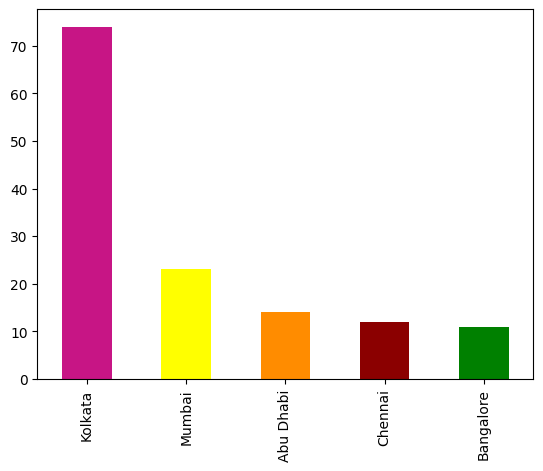

In [51]:
# Ploting

kkr_cities[0:5].plot(kind = 'bar', color = ['mediumvioletred', 'yellow', 'darkorange', 'darkred', 'green'])

# We can also use lightgreen, lightyellow, mediumvioletred and so on

# `Q-10:` Find out the average margin for the team Mumbai Indians for only the session 2011.

In [54]:
records, man_of_match = team1_vs_team2('Chennai Super Kings', 'Mumbai Indians', df = ipl)

In [65]:
(records[records['WinningTeam'] == 'Chennai Super Kings']).count()

Team1          14
Team2          14
WinningTeam    14
dtype: int64